# 01 · Análisis exploratorio: Airbnb en España y renta de la zona

## Introducción

Este notebook recorre la parte exploratoria del proyecto final del Máster en Data Analytics. La pregunta de
negocio es **qué explica el precio por noche de un alojamiento turístico en España y cómo se relaciona con la
renta de la zona en la que está**. Para responderla se combinan dos fuentes públicas e independientes:

1. **Inside Airbnb**, que publica los anuncios visibles en Airbnb el día del scrape para nueve ciudades y regiones
   españolas (Madrid, Barcelona, Valencia, Sevilla, Málaga, Girona, Mallorca, Menorca y Euskadi).
2. **El Atlas de Distribución de Renta de los Hogares (ADRH) del INE**, con la renta, la desigualdad y varios
   indicadores demográficos por municipio y por distrito censal.

El recorrido es el de cualquier análisis de datos: cargar las dos fuentes y comprobar qué contienen, unirlas,
revisar la calidad antes y después de limpiar, y describir el conjunto final con tablas y figuras. El análisis
estadístico formal (contrastes, regresión y modelo predictivo) está en el notebook `02_analisis_estadistico`.

**Cómo se calculan las cifras.** Las cifras que aparecen en el texto salen de dos sitios: de
`reports/findings.json`, que genera `python run_pipeline.py`, o de operaciones pandas hechas en la propia celda.
Ninguna está escrita a mano. Además de leer resultados, aquí se hacen operaciones pandas explícitas
(`groupby().agg`, `crosstab`, `merge` y `pivot_table`) para que se vea cómo se construyen las tablas.

**Una advertencia que vale para todo el notebook:** los datos son observacionales. Cuando se dice que el
precio «se asocia» con algo, no se afirma que ese algo lo cause.

El notebook se genera desde `notebooks/fuentes_py/01_eda.py` con `python scripts/ejecutar_notebooks.py`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import config, formato as fmt, fuentes, visualizacion as viz
from src.analisis import ETIQUETAS_VARIABLES, NOMBRE_CIUDAD

logging.disable(logging.WARNING)
%matplotlib inline
viz.configurar_estilo()
plt.rcParams["figure.dpi"] = 60  # imágenes incrustadas ligeras (las del informe se guardan a 150 dpi)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
with open(config.RUTA_CALIDAD, encoding="utf-8") as f:
    calidad = json.load(f)
D, E = findings["descriptivo"], findings["estadistica"]


def lectura(texto: str) -> None:
    """Muestra una interpretación en Markdown (las cifras van dentro del f-string, nunca a mano)."""
    display(Markdown(texto))

## 1. Fuente 1: los anuncios de Inside Airbnb

Cada ciudad tiene su propio `listings.csv.gz`. La función `fuentes.leer_listings_espana` comprueba antes el hash
SHA-256 de cada fichero contra el manifiesto (para estar seguros de que se analiza exactamente lo descargado) y
los concatena, añadiendo dos columnas: la ciudad y la fecha del snapshot. Con `groupby().agg` se resume cuántos
anuncios hay por ciudad, cuántos publican precio y en qué fecha se tomó cada snapshot.

In [2]:
listings = fuentes.leer_listings_espana()
precio_texto = listings["price"].astype("string").str.replace(r"[$,]", "", regex=True)
listings["precio_num"] = pd.to_numeric(precio_texto, errors="coerce")
resumen_fuente1 = (listings.groupby("ciudad")
                   .agg(anuncios=("id", "size"), con_precio=("precio_num", lambda s: (s > 0).sum()),
                        snapshot=("fecha_snapshot", "first"), anfitriones=("host_id", "nunique"))
                   .rename(index=NOMBRE_CIUDAD))
resumen_fuente1.loc["Total"] = [resumen_fuente1["anuncios"].sum(), resumen_fuente1["con_precio"].sum(), "",
                                listings["host_id"].nunique()]
print(f"Inside Airbnb: {fmt.n0(listings.shape[0])} anuncios × {fmt.n0(listings.shape[1] - 1)} columnas")
resumen_fuente1

Inside Airbnb: 109.437 anuncios × 92 columnas


,anuncios,con_precio,snapshot,anfitriones
ciudad,,,,
Barcelona,15236,12610,2026-09-17,4586
Euskadi,6248,5540,2026-09-25,3094
Girona,20470,15136,2026-09-25,7665
Madrid,23109,18785,2026-09-17,8704
Málaga,9505,8528,2026-09-28,3318
Mallorca,14901,11082,2026-09-19,4021
Menorca,3625,3013,2026-09-28,1355
Sevilla,8375,7723,2026-09-25,3014
Valencia,7968,7197,2026-09-20,3215


In [3]:
grande = resumen_fuente1.drop(index="Total")["anuncios"].astype(int)
lectura(f"**Lectura.** La fuente 1 aporta {fmt.n0(grande.sum())} anuncios. La zona con más anuncios es "
        f"{grande.idxmax()} ({fmt.n0(grande.max())}) y la que menos {grande.idxmin()} ({fmt.n0(grande.min())}). "
        f"Los snapshots se tomaron entre el {findings['meta']['snapshot_min']} y el {findings['meta']['snapshot_max']}: "
        "son fotos casi simultáneas, pero no idénticas, y por eso se conserva la fecha de cada una. Una parte de los "
        "anuncios no publica precio; se verá más abajo que esos huecos no son aleatorios.")

**Lectura.** La fuente 1 aporta 109.437 anuncios. La zona con más anuncios es Madrid (23.109) y la que menos Menorca (3.625). Los snapshots se tomaron entre el 2026-09-17 y el 2026-09-28: son fotos casi simultáneas, pero no idénticas, y por eso se conserva la fecha de cada una. Una parte de los anuncios no publica precio; se verá más abajo que esos huecos no son aleatorios.

## 2. Fuente 2: la renta del INE

El ADRH se publica en tablas provinciales en formato largo: una fila por territorio, indicador y año.
`fuentes.leer_adrh` las lee todas (verificando también sus hashes) y `fuentes.elegir_anio_adrh` elige el año
más reciente en el que todos los indicadores tienen dato en la mayoría de los distritos. Con `pivot_table` se
pasa del formato largo a una tabla ancha, con una columna por indicador, que es la forma que necesita la unión.

In [4]:
largo = fuentes.leer_adrh()
anio = fuentes.elegir_anio_adrh(largo)
print(f"ADRH: {fmt.n0(len(largo))} filas en formato largo; año elegido: {anio}")
print("Niveles territoriales:", largo["nivel"].value_counts().to_dict())
distritos_anio = largo[(largo["nivel"] == "distrito") & (largo["periodo"] == anio)
                       & largo["indicador"].isin(config.INDICADORES_ADRH)]
ancho = distritos_anio.pivot_table(index="codigo", columns="indicador", values="valor", aggfunc="first")
ancho = ancho.rename(columns=config.INDICADORES_ADRH)
ancho[["renta_neta_persona", "renta_mediana_uc", "gini", "edad_media", "pct_hogares_unipersonales"]].describe().round(1)

ADRH: 4.038.746 filas en formato largo; año elegido: 2024
Niveles territoriales: {'seccion': 3262638, 'distrito': 463330, 'municipio': 312778}


indicador,renta_neta_persona,renta_mediana_uc,gini,edad_media,pct_hogares_unipersonales
count,2209.0,2197.0,2201.0,2220.0,2220.0
mean,16504.1,21953.8,28.4,44.3,29.0
std,3703.1,4675.1,3.6,3.0,7.5
min,7558.0,10850.0,19.7,32.7,11.0
25%,13804.0,18550.0,26.0,42.3,24.1
50%,16374.0,22050.0,27.9,43.9,28.1
75%,18558.0,24850.0,30.2,45.9,32.7
max,38797.0,47250.0,44.8,61.7,70.9


In [5]:
lectura(f"**Lectura.** Para {anio} hay {fmt.n0(len(ancho))} distritos censales con datos en las provincias "
        f"descargadas. La renta neta media por persona va de {fmt.eur0(ancho['renta_neta_persona'].min())} a "
        f"{fmt.eur0(ancho['renta_neta_persona'].max())} y su mediana es "
        f"{fmt.eur0(ancho['renta_neta_persona'].median())}. Es una variedad suficiente como para preguntarse si los "
        "anuncios de zonas más ricas son más caros. Conviene recordar que es renta de "
        f"{anio} y que los anuncios son de 2026: es contexto socioeconómico de la zona, no un dato simultáneo.")

**Lectura.** Para 2024 hay 2.220 distritos censales con datos en las provincias descargadas. La renta neta media por persona va de 7.558 € a 38.797 € y su mediana es 16.374 €. Es una variedad suficiente como para preguntarse si los anuncios de zonas más ricas son más caros. Conviene recordar que es renta de 2024 y que los anuncios son de 2026: es contexto socioeconómico de la zona, no un dato simultáneo.

## 3. Unión de las dos fuentes

Inside Airbnb y el INE no comparten ningún identificador. La unión es geográfica: cada anuncio se sitúa en la
sección censal que contiene sus coordenadas (punto en polígono con el seccionado oficial del INE). El código de
sección tiene diez dígitos; los siete primeros son el distrito censal y los cinco primeros el municipio, que son
las claves del ADRH. El cálculo geométrico ya está hecho y guardado en `data/interim/asignacion_secciones.csv.gz`,
así que aquí se reproduce la unión con un `merge` explícito.

In [6]:
asignacion = fuentes.asegurar_asignacion(listings)
base = listings.merge(asignacion[["ciudad", "id", "codigo_seccion_ine"]], on=["ciudad", "id"], how="left",
                      validate="one_to_one")
base["codigo_distrito_ine"] = base["codigo_seccion_ine"].astype("string").str[:7]
renta_distrito = ancho[["renta_neta_persona", "gini"]].add_prefix("ine_dis_")
unido_nb = base.merge(renta_distrito, left_on="codigo_distrito_ine", right_index=True, how="left",
                      validate="many_to_one")
tasa = (unido_nb.assign(con_ine=unido_nb["ine_dis_renta_neta_persona"].notna())
        .groupby("ciudad")["con_ine"].agg(anuncios="size", con_dato_ine="sum", pct="mean")
        .rename(index=NOMBRE_CIUDAD))
tasa["pct"] = (tasa["pct"] * 100).round(2)
print(f"Filas antes y después del merge: {fmt.n0(len(listings))} → {fmt.n0(len(unido_nb))}")
tasa

Filas antes y después del merge: 109.437 → 109.437


,anuncios,con_dato_ine,pct
ciudad,,,
Barcelona,15236,15236,100.00
Euskadi,6248,6225,99.63
Girona,20470,20266,99.00
Madrid,23109,23109,100.00
Málaga,9505,9498,99.93
Mallorca,14901,14785,99.22
Menorca,3625,3549,97.90
Sevilla,8375,8375,100.00
Valencia,7968,7967,99.99


In [7]:
total = findings["dataset"]["union"]["total"]
lectura(f"**Lectura.** El `merge` es un *left join*: no pierde ningún anuncio ({fmt.n0(len(unido_nb))} filas antes y "
        f"después). Recibe dato del INE el {fmt.pct2(unido_nb['ine_dis_renta_neta_persona'].notna().mean() * 100)} "
        f"de los anuncios, la misma cifra que calcula el pipeline ({fmt.pct2(total['pct_distrito'])}). Los "
        f"{fmt.n0(findings['dataset']['union']['n_sin_emparejar'])} que quedan sin dato están casi todos en la costa "
        "de las regiones: la anonimización de coordenadas de Airbnb desplaza algunos puntos al mar, fuera de toda "
        "sección. Se conservan con valores vacíos en lugar de borrarlos o de asignarles una zona inventada. Como "
        f"validación, la unidad asignada coincide con la que declara Inside Airbnb en el "
        f"{fmt.pct2(findings['dataset']['union']['concordancia_total']['pct_coinciden'])} de los anuncios validados.")

**Lectura.** El `merge` es un *left join*: no pierde ningún anuncio (109.437 filas antes y después). Recibe dato del INE el 99,61 % de los anuncios, la misma cifra que calcula el pipeline (99,61 %). Los 427 que quedan sin dato están casi todos en la costa de las regiones: la anonimización de coordenadas de Airbnb desplaza algunos puntos al mar, fuera de toda sección. Se conservan con valores vacíos en lugar de borrarlos o de asignarles una zona inventada. Como validación, la unidad asignada coincide con la que declara Inside Airbnb en el 99,58 % de los anuncios validados.

## 4. Calidad de datos antes y después de limpiar

El conjunto unido completo tiene muchas columnas que no hacen falta (URLs, textos largos, datos personales del
anfitrión) y problemas típicos de un scrape: precios en texto con símbolo de dólar, booleanos como `t`/`f`,
baños descritos en texto y nombres con doble codificación en Euskadi. La limpieza los resuelve con reglas
documentadas y cuenta cuántas filas afecta cada una, **también por ciudad**. Primero, el perfil global antes y
después.

In [8]:
claves = ("filas", "columnas", "nulos_total", "pct_nulos_total", "columnas_con_nulos")
pd.DataFrame({"antes (conjunto unido)": {k: calidad["antes"][k] for k in claves},
              "después (conjunto final)": {k: calidad["despues"][k] for k in claves}})

,antes (conjunto unido),después (conjunto final)
filas,1.094370e+05,109437.000000
columnas,1.290000e+02,73.000000
nulos_total,2.020368e+06,191243.000000
pct_nulos_total,1.431122e+01,2.393859
columnas_con_nulos,8.700000e+01,27.000000


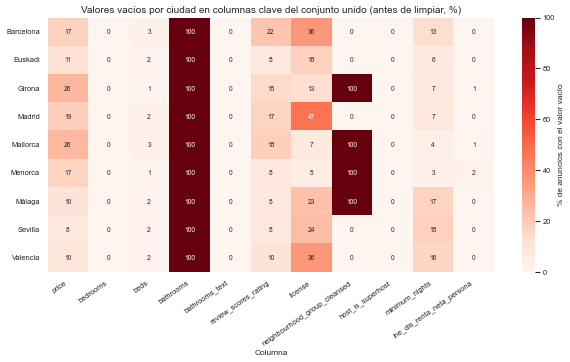

In [9]:
viz.fig_calidad_nulos(calidad);

In [10]:
nulos = pd.DataFrame({NOMBRE_CIUDAD[c]: v["antes"]["nulos_pct"] for c, v in calidad["por_ciudad"].items()}).T
sin_distrito = nulos.index[nulos["neighbourhood_group_cleansed"] == 100].tolist()
lectura(f"**Lectura.** El precio es la columna clave con más huecos: va del {fmt.pct1(nulos['price'].min())} en "
        f"{nulos['price'].idxmin()} al {fmt.pct1(nulos['price'].max())} en {nulos['price'].idxmax()}. "
        f"La columna de distrito está vacía por completo en {', '.join(sin_distrito)}: en esas zonas Inside Airbnb "
        "solo informa del municipio o del barrio, y por eso el análisis compara ciudades con la ciudad y con el "
        "distrito censal del INE, que sí existe en todas. Dormitorios, camas y baños apenas tienen huecos tras "
        "reconstruirlos.")

**Lectura.** El precio es la columna clave con más huecos: va del 7,8 % en Sevilla al 26,1 % en Girona. La columna de distrito está vacía por completo en Girona, Málaga, Mallorca, Menorca: en esas zonas Inside Airbnb solo informa del municipio o del barrio, y por eso el análisis compara ciudades con la ciudad y con el distrito censal del INE, que sí existe en todas. Dormitorios, camas y baños apenas tienen huecos tras reconstruirlos.

Las reglas de limpieza por ciudad muestran dónde se concentra cada problema. Las vallas de atípicos se calculan
una sola vez sobre el logaritmo del precio de todo el conjunto, para que «atípico» signifique lo mismo en todas
las ciudades; después se cuenta cuántos caen en cada una.

In [11]:
reglas = pd.DataFrame({NOMBRE_CIUDAD[c]: v["reglas"] for c, v in calidad["por_ciudad"].items()}).T
reglas[["filas", "pct_precio_nulo", "precio_cero", "outliers_total", "pct_outliers", "larga_estancia",
        "minimum_nights_extremo", "fuera_bbox_o_nulas"]].round(1)

,filas,pct_precio_nulo,precio_cero,outliers_total,pct_outliers,larga_estancia,minimum_nights_extremo,fuera_bbox_o_nulas
Barcelona,15236.0,17.2,0.0,586.0,4.6,5408.0,4.0,0.0
Euskadi,6248.0,11.3,0.0,103.0,1.9,264.0,0.0,0.0
Girona,20470.0,26.1,0.0,407.0,2.7,409.0,1.0,0.0
Madrid,23109.0,18.7,0.0,761.0,4.1,3151.0,8.0,0.0
Málaga,9505.0,10.3,0.0,202.0,2.4,195.0,2.0,0.0
Mallorca,14901.0,25.6,0.0,1304.0,11.8,691.0,0.0,0.0
Menorca,3625.0,16.9,0.0,105.0,3.5,44.0,0.0,0.0
Sevilla,8375.0,7.8,0.0,136.0,1.8,181.0,0.0,0.0
Valencia,7968.0,9.7,0.0,178.0,2.5,290.0,1.0,0.0


In [12]:
lp = findings["limpieza"]
lectura(f"**Lectura.** Las vallas de Tukey sobre ln(precio) quedan en {fmt.eur2(lp['outliers']['valla_inf'])} y "
        f"{fmt.eur2(lp['outliers']['valla_sup'])}. {reglas['pct_outliers'].idxmax()} concentra la mayor proporción de "
        f"atípicos ({fmt.pct1(reglas['pct_outliers'].max())} de sus anuncios con precio), lo que encaja con un mercado "
        "de alojamientos caros que no tienen por qué ser errores: por eso se marcan pero no se borran, y el notebook 02 "
        f"repite los análisis sin ellos. Las estancias mínimas de {config.MIN_NIGHTS_LARGA_ESTANCIA} noches o más pesan sobre todo en "
        f"{reglas['larga_estancia'].idxmax()} ({fmt.n0(reglas['larga_estancia'].max())} anuncios), un mercado de "
        "alquiler de temporada con precios por noche muy distintos. Ninguna coordenada cae fuera de la envolvente de "
        "su ciudad. El precio no se imputa: el "
        f"{fmt.pct1(lp['precio']['pct_nulos_sin_disponibilidad'])} de los precios vacíos son anuncios sin ningún día "
        "disponible, así que el análisis de precio describe solo la oferta reservable (sesgo de selección).")

**Lectura.** Las vallas de Tukey sobre ln(precio) quedan en 31,61 € y 966,29 €. Mallorca concentra la mayor proporción de atípicos (11,8 % de sus anuncios con precio), lo que encaja con un mercado de alojamientos caros que no tienen por qué ser errores: por eso se marcan pero no se borran, y el notebook 02 repite los análisis sin ellos. Las estancias mínimas de 30 noches o más pesan sobre todo en Barcelona (5.408 anuncios), un mercado de alquiler de temporada con precios por noche muy distintos. Ninguna coordenada cae fuera de la envolvente de su ciudad. El precio no se imputa: el 54,2 % de los precios vacíos son anuncios sin ningún día disponible, así que el análisis de precio describe solo la oferta reservable (sesgo de selección).

## 5. El conjunto final

El conjunto final procesado se guarda en Parquet con una selección de columnas: las del anuncio que usa el
análisis, las claves de la unión y siete indicadores del INE por distrito y por municipio. El pipeline comprueba
que cumple los requisitos del enunciado (al menos 50.000 filas y 20 columnas) y se detiene si no. Aquí se lee y se
vuelve a comprobar.

In [13]:
df = pd.read_parquet(config.RUTA_PARQUET)
cp = df[df["precio_valido"]].assign(nombre_ciudad=lambda d: d["ciudad"].map(NOMBRE_CIUDAD))
print(f"Conjunto final: {fmt.n0(df.shape[0])} filas × {fmt.n0(df.shape[1])} columnas "
      f"({sum(c.startswith('ine_') for c in df.columns)} del INE)")
print("¿Cumple ≥ 50.000 filas y ≥ 20 columnas?", df.shape[0] >= config.MIN_FILAS_UNION and df.shape[1] >= config.MIN_COLUMNAS_UNION)
df.dtypes.astype(str).value_counts().to_frame("columnas")

Conjunto final: 109.437 filas × 73 columnas (14 del INE)
¿Cumple ≥ 50.000 filas y ≥ 20 columnas? True


,columnas
float64,26
bool,25
int64,8
string,7
str,5
category,2


## 6. Precio: distribución y ciudades

**Qué es el precio.** `price` es el precio por noche de una cotización concreta que Inside Airbnb pide a Airbnb
para unas fechas. Ya incluye los descuentos aplicables y no incluye tasas. No es lo que pagó un huésped.

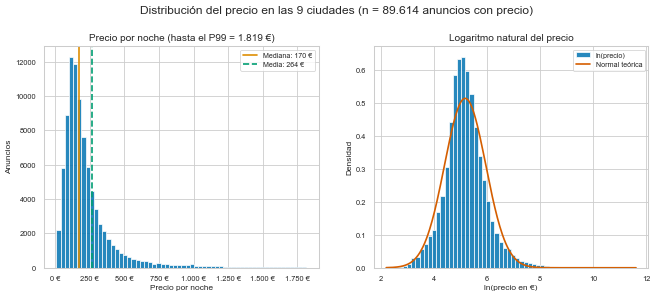

In [14]:
viz.fig_distribucion_precio(df);

In [15]:
p = cp["price"]
lectura(f"**Lectura.** El precio es muy asimétrico: la mediana es {fmt.eur2(p.median())} y la media "
        f"{fmt.eur2(p.mean())}, arrastrada por una cola de anuncios muy caros (el máximo es {fmt.eur0(p.max())}). "
        f"La asimetría es {fmt.n2(D['precio']['asimetria'])}. En logaritmo la distribución es casi simétrica "
        f"(asimetría {fmt.n2(D['log_precio']['asimetria'])}), por eso los modelos trabajan con ln(precio) y las "
        "comparaciones usan contrastes basados en rangos.")

**Lectura.** El precio es muy asimétrico: la mediana es 170,00 € y la media 263,99 €, arrastrada por una cola de anuncios muy caros (el máximo es 110.700 €). La asimetría es 84,48. En logaritmo la distribución es casi simétrica (asimetría 0,57), por eso los modelos trabajan con ln(precio) y las comparaciones usan contrastes basados en rangos.

Con `groupby().agg` se calcula el resumen de precio por ciudad. Se informan mediana y cuartiles porque la media
está muy influida por la cola de precios altos.

In [16]:
por_ciudad = (cp.groupby("nombre_ciudad")["price"]
              .agg(n="size", mediana="median", media="mean", q1=lambda s: s.quantile(0.25),
                   q3=lambda s: s.quantile(0.75))
              .sort_values("mediana", ascending=False).round(1))
por_ciudad

,n,mediana,media,q1,q3
nombre_ciudad,,,,,
Mallorca,11082,311.8,528.4,202.5,545.0
Barcelona,12610,190.7,253.4,93.4,284.0
Menorca,3013,190.0,307.8,130.0,326.0
Girona,15136,170.5,261.8,120.0,273.0
Euskadi,5540,160.3,218.6,113.0,241.0
Sevilla,7723,158.0,203.0,118.5,220.0
Madrid,18785,151.0,208.6,95.4,224.5
Málaga,8528,150.0,213.3,112.0,209.0
Valencia,7197,134.1,166.7,98.3,183.0


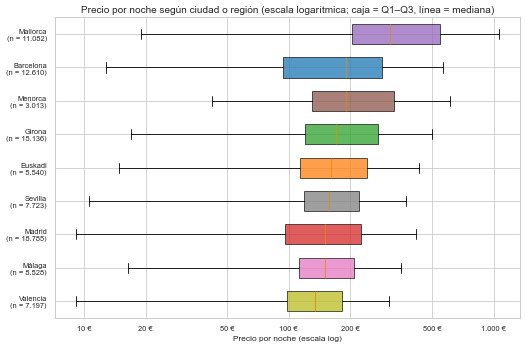

In [17]:
viz.fig_precio_por_ciudad(df);

In [18]:
lectura(f"**Lectura.** {por_ciudad.index[0]} es la zona más cara (mediana {fmt.eur0(por_ciudad['mediana'].iloc[0])}) "
        f"y {por_ciudad.index[-1]} la más barata ({fmt.eur0(por_ciudad['mediana'].iloc[-1])}). Las cajas se solapan "
        f"mucho: el ε² de Kruskal-Wallis por ciudad es {fmt.n3(E['kruskal_ciudad']['tamano_efecto']['valor'])}, así que "
        "la ciudad explica una parte moderada de la variación y dentro de cada ciudad queda mucha. Las tres zonas más "
        f"caras son {', '.join(por_ciudad.index[:3])}.")

**Lectura.** Mallorca es la zona más cara (mediana 312 €) y Valencia la más barata (134 €). Las cajas se solapan mucho: el ε² de Kruskal-Wallis por ciudad es 0,114, así que la ciudad explica una parte moderada de la variación y dentro de cada ciudad queda mucha. Las tres zonas más caras son Mallorca, Barcelona, Menorca.

## 7. Tipo de habitación y capacidad

`pd.crosstab` con `normalize="index"` da el reparto de tipos de habitación dentro de cada ciudad (cada fila suma
100 %).

In [19]:
mix = (pd.crosstab(cp["nombre_ciudad"], cp["tipo_habitacion_agrupado"], normalize="index") * 100).round(1)
mix.sort_values(mix.columns[0], ascending=False)

tipo_habitacion_agrupado,Alojamiento entero,Habitación compartida,Habitación de hotel,Habitación privada
nombre_ciudad,,,,
Menorca,96.3,0.0,0.3,3.4
Girona,93.7,0.1,0.1,6.2
Mallorca,92.3,0.0,0.3,7.4
Málaga,89.4,0.4,0.0,10.1
Sevilla,87.2,0.3,0.2,12.3
Valencia,79.5,0.2,0.2,20.1
Barcelona,74.4,0.9,0.6,24.1
Euskadi,73.0,0.8,0.9,25.3
Madrid,72.2,0.7,0.2,26.9


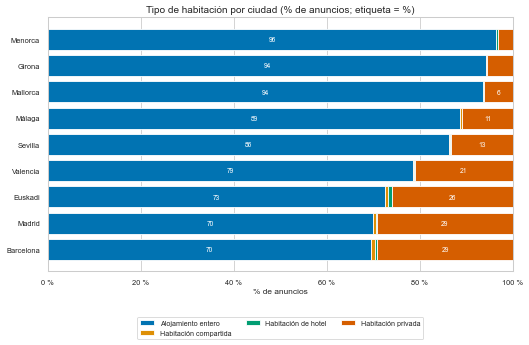

In [20]:
viz.fig_tipo_por_ciudad(findings);

In [21]:
entero = mix["Alojamiento entero"]
lectura(f"**Lectura.** El alojamiento entero domina en todas partes, pero con diferencias: es el "
        f"{fmt.pct1(entero.max())} de los anuncios con precio en {entero.idxmax()} y solo el "
        f"{fmt.pct1(entero.min())} en {entero.idxmin()}, donde las habitaciones privadas tienen más peso. Esto "
        "importa para comparar ciudades: parte de la diferencia de precio entre ciudades es una diferencia en el "
        "tipo de producto, y por eso la regresión del notebook 02 controla el tipo de habitación.")

**Lectura.** El alojamiento entero domina en todas partes, pero con diferencias: es el 96,3 % de los anuncios con precio en Menorca y solo el 72,2 % en Madrid, donde las habitaciones privadas tienen más peso. Esto importa para comparar ciudades: parte de la diferencia de precio entre ciudades es una diferencia en el tipo de producto, y por eso la regresión del notebook 02 controla el tipo de habitación.

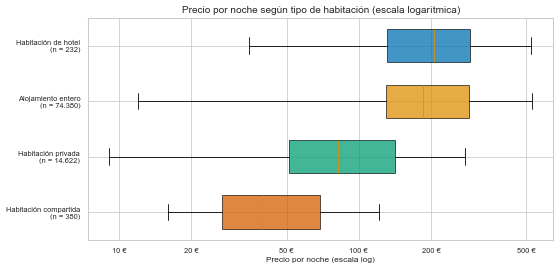

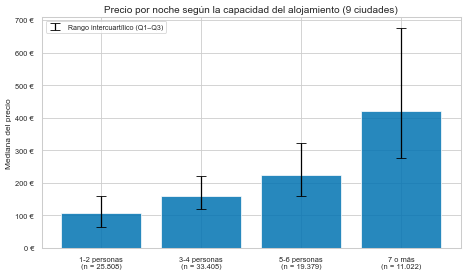

In [22]:
viz.fig_precio_por_tipo(df);
viz.fig_precio_por_capacidad(findings);

In [23]:
pt = cp.pivot_table(index="categoria_capacidad", columns="tipo_habitacion_agrupado", values="price",
                    aggfunc="median", observed=True).round(0)
pt

tipo_habitacion_agrupado,Alojamiento entero,Habitación compartida,Habitación de hotel,Habitación privada
categoria_capacidad,,,,
1-2 personas,132.0,36.0,176.0,74.0
3-4 personas,161.0,91.0,206.0,135.0
5-6 personas,224.0,72.0,270.0,184.0
7 o más,425.0,51.0,619.0,315.0


In [24]:
caps = D["por_capacidad"]
lectura(f"**Lectura.** El precio crece con la capacidad en cada tramo: de {fmt.eur0(caps[0]['mediana'])} para "
        f"{caps[0]['grupo']} a {fmt.eur0(caps[-1]['mediana'])} para {caps[-1]['grupo']}. La tabla dinámica "
        "(`pivot_table`) muestra que el patrón se repite dentro del alojamiento entero, así que no se debe solo a que "
        "las habitaciones privadas sean pequeñas. Los tipos minoritarios tienen pocos anuncios con precio "
        f"({fmt.n0((cp['tipo_habitacion'] == 'Habitación de hotel').sum())} de hotel y "
        f"{fmt.n0((cp['tipo_habitacion'] == 'Habitación compartida').sum())} compartidas), así que sus medianas por "
        "tramo son poco estables.")

**Lectura.** El precio crece con la capacidad en cada tramo: de 107 € para 1-2 personas a 422 € para 7 o más. La tabla dinámica (`pivot_table`) muestra que el patrón se repite dentro del alojamiento entero, así que no se debe solo a que las habitaciones privadas sean pequeñas. Los tipos minoritarios tienen pocos anuncios con precio (232 de hotel y 380 compartidas), así que sus medianas por tramo son poco estables.

## 8. Anfitriones y licencias

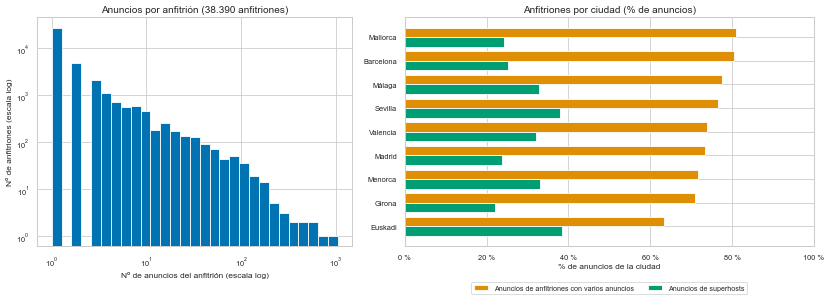

In [25]:
viz.fig_anfitriones(df, findings);

In [26]:
h = D["hosts"]
lectura(f"**Lectura.** Hay {fmt.n0(h['n_hosts'])} anfitriones. El {fmt.pct1(h['pct_hosts_un_anuncio'])} tiene un solo "
        f"anuncio, pero esos anfitriones pequeños suman poca oferta: el {fmt.pct1(h['pct_anuncios_multianuncio'])} de los "
        "anuncios es de anfitriones con varios, y los "
        f"{fmt.n0(h['n_hosts_top1pct'])} anfitriones con más anuncios (el uno por ciento) reúnen el "
        f"{fmt.pct1(h['pct_anuncios_top1pct_hosts'])}. El histograma en doble escala logarítmica lo refleja: muchos "
        "anfitriones con uno o dos anuncios y unos pocos con cientos. Tener varios anuncios no dice por sí solo quién "
        "gestiona el alojamiento.")

**Lectura.** Hay 38.390 anfitriones. El 70,2 % tiene un solo anuncio, pero esos anfitriones pequeños suman poca oferta: el 75,0 % de los anuncios es de anfitriones con varios, y los 384 anfitriones con más anuncios (el uno por ciento) reúnen el 28,6 %. El histograma en doble escala logarítmica lo refleja: muchos anfitriones con uno o dos anuncios y unos pocos con cientos. Tener varios anuncios no dice por sí solo quién gestiona el alojamiento.

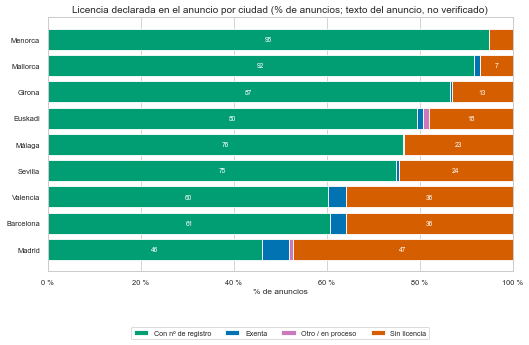

In [27]:
viz.fig_licencias_por_ciudad(findings);

In [28]:
lic = pd.DataFrame(D["licencia_por_ciudad_pct"]).T
lectura(f"**Lectura.** El porcentaje de anuncios sin ningún número de licencia va del "
        f"{fmt.pct1(lic['Sin licencia'].min())} en {lic['Sin licencia'].idxmin()} al "
        f"{fmt.pct1(lic['Sin licencia'].max())} en {lic['Sin licencia'].idxmax()}. Es lo que declara el texto del "
        "anuncio, sin verificar en ningún registro oficial; además las exenciones (por ejemplo, el alquiler de "
        "temporada) dependen de cada comunidad autónoma, así que no se puede leer como un porcentaje de ilegalidad.")

**Lectura.** El porcentaje de anuncios sin ningún número de licencia va del 5,0 % en Menorca al 47,2 % en Madrid. Es lo que declara el texto del anuncio, sin verificar en ningún registro oficial; además las exenciones (por ejemplo, el alquiler de temporada) dependen de cada comunidad autónoma, así que no se puede leer como un porcentaje de ilegalidad.

## 9. Ocupación (proxy)

No hay datos de reservas. Se usan dos aproximaciones distintas: el porcentaje de días no disponibles en el
calendario de los próximos 365 días (mezcla reservas y bloqueos del anfitrión) y la ocupación que estima Inside
Airbnb para los últimos doce meses a partir de las reseñas.

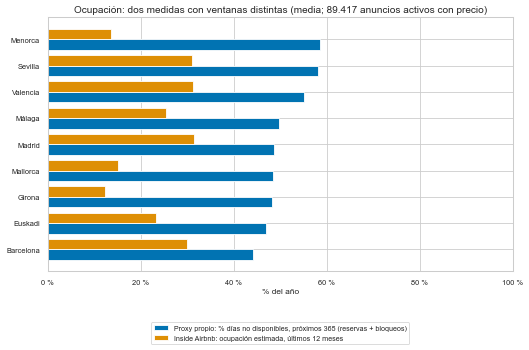

In [29]:
viz.fig_ocupacion(df, findings);

In [30]:
oc = D["ocupacion"]
lectura(f"**Lectura.** La media del proxy de días no disponibles es {fmt.pct1(oc['no_disponible_media'])} y la de "
        f"Inside Airbnb {fmt.pct1(oc['ocupacion_inside_airbnb_media'])}. Que el proxy sea mayor es lo esperable: "
        "incluye bloqueos y mira hacia delante. Ambas medidas apenas se correlacionan entre anuncios "
        f"(ρ = {fmt.n2(oc['spearman'])}), así que ninguna debe leerse como ocupación real.")

**Lectura.** La media del proxy de días no disponibles es 49,6 % y la de Inside Airbnb 24,3 %. Que el proxy sea mayor es lo esperable: incluye bloqueos y mira hacia delante. Ambas medidas apenas se correlacionan entre anuncios (ρ = 0,23), así que ninguna debe leerse como ocupación real.

## 10. Distribución territorial: precio y renta

Dos juegos de mapas pequeños, uno por ciudad, con escala de color común. El primero colorea cada anuncio por su
precio; el segundo por la renta neta por persona del distrito censal en que cae.

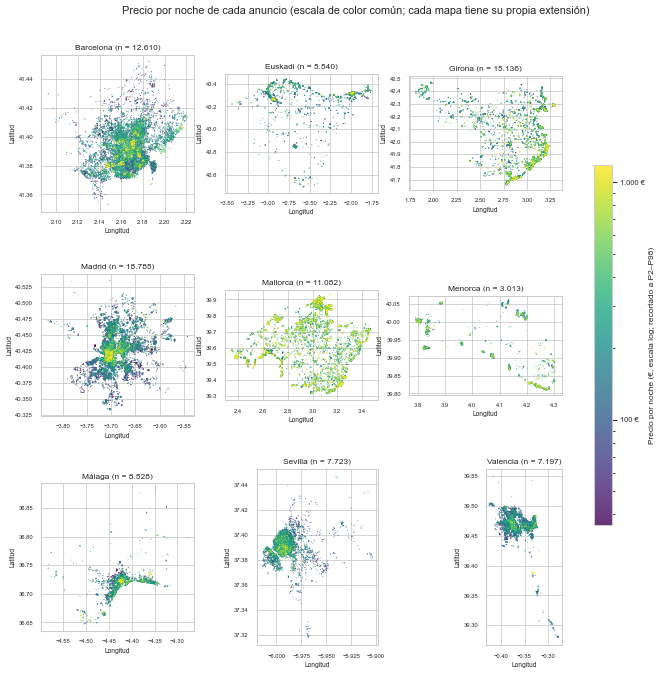

In [31]:
viz.fig_mapa_precio(df);

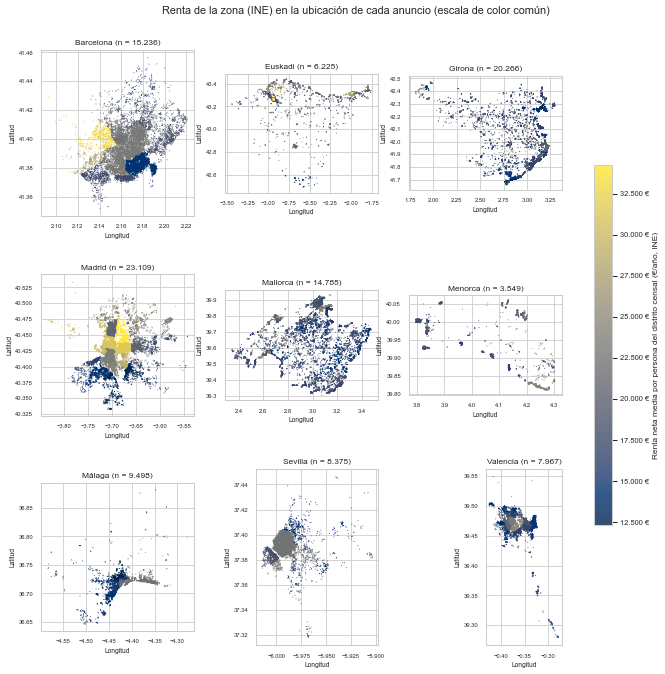

In [32]:
viz.fig_mapa_renta(df);

In [33]:
renta_ciudad = (df.assign(nombre_ciudad=df["ciudad"].map(NOMBRE_CIUDAD))
                .groupby("nombre_ciudad")[config.RENTA_PRINCIPAL].agg(["median", "min", "max"]).round(0))
union_tablas = por_ciudad[["mediana"]].merge(renta_ciudad, left_index=True, right_index=True)
union_tablas.columns = ["mediana_precio", "renta_mediana", "renta_min", "renta_max"]
union_tablas.sort_values("mediana_precio", ascending=False)

,mediana_precio,renta_mediana,renta_min,renta_max
nombre_ciudad,,,,
Mallorca,311.8,17066.0,13350.0,25810.0
Barcelona,190.7,22141.0,14323.0,32927.0
Menorca,190.0,18610.0,15170.0,24377.0
Girona,170.5,15916.0,11219.0,27415.0
Euskadi,160.3,20677.0,11313.0,34744.0
Sevilla,158.0,22106.0,10503.0,23355.0
Madrid,151.0,23342.0,12754.0,34254.0
Málaga,150.0,15082.0,11063.0,22048.0
Valencia,134.1,16822.0,13031.0,24861.0


In [34]:
rho_ciudades = union_tablas["mediana_precio"].corr(union_tablas["renta_mediana"], method="spearman")
lectura(f"**Lectura.** Los mapas muestran que la oferta se concentra en los centros urbanos y, en las regiones, en "
        "la costa. La tabla, construida con un `merge` entre el resumen de precio y el de renta, pone las dos cosas "
        "juntas: entre las nueve zonas, la correlación de Spearman entre la mediana del precio y la renta mediana es "
        f"{fmt.n2(rho_ciudades)}. La zona más cara, {union_tablas['mediana_precio'].idxmax()}, tiene una renta "
        f"mediana de {fmt.eur0(union_tablas.loc[union_tablas['mediana_precio'].idxmax(), 'renta_mediana'])}, y la de "
        f"más renta, {union_tablas['renta_mediana'].idxmax()}, no es la más cara. A primera vista, entre ciudades la "
        "renta no ordena los precios. El notebook 02 mira qué pasa dentro de cada ciudad.")

**Lectura.** Los mapas muestran que la oferta se concentra en los centros urbanos y, en las regiones, en la costa. La tabla, construida con un `merge` entre el resumen de precio y el de renta, pone las dos cosas juntas: entre las nueve zonas, la correlación de Spearman entre la mediana del precio y la renta mediana es 0,20. La zona más cara, Mallorca, tiene una renta mediana de 17.066 €, y la de más renta, Madrid, no es la más cara. A primera vista, entre ciudades la renta no ordena los precios. El notebook 02 mira qué pasa dentro de cada ciudad.

## 11. Correlaciones y amenities

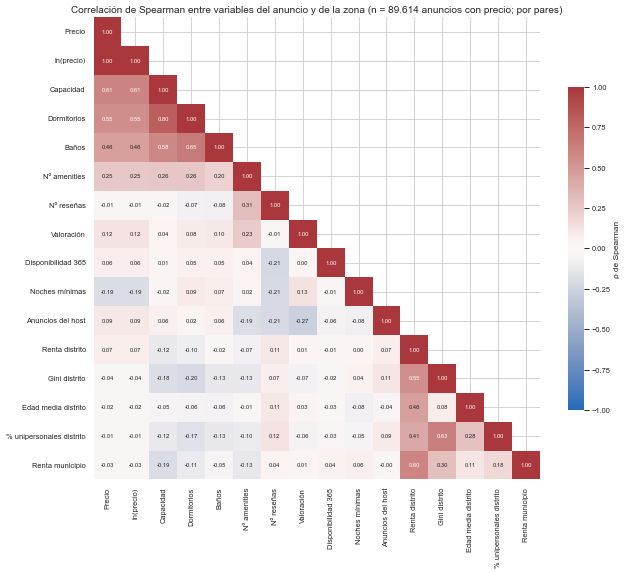

In [35]:
viz.fig_correlaciones(findings);

In [36]:
corr = D["correlaciones"]["con_precio_por_variable"]
sp = pd.DataFrame(D["correlaciones"]["spearman"])
ine_vars = [v for v in sp.columns if v.startswith("ine_")]
par_ine = max(((a, b, sp.loc[a, b]) for i, a in enumerate(ine_vars) for b in ine_vars[i + 1:]), key=lambda x: abs(x[2]))
par_ine = (ETIQUETAS_VARIABLES.get(par_ine[0], par_ine[0]), ETIQUETAS_VARIABLES.get(par_ine[1], par_ine[1]), par_ine[2])
lectura(f"**Lectura.** Las variables del propio alojamiento son las más correlacionadas con el precio: capacidad "
        f"(ρ = {fmt.n2(corr['accommodates']['spearman'])}), dormitorios ({fmt.n2(corr['bedrooms']['spearman'])}) y "
        f"baños ({fmt.n2(corr['bathrooms']['spearman'])}). La renta del distrito apenas se correlaciona con el precio "
        f"en el conjunto (ρ = {fmt.n3(corr['ine_dis_renta_neta_persona']['spearman'])}) y la del municipio menos aún "
        f"({fmt.n3(corr['ine_mun_renta_neta_persona']['spearman'])}). Entre las propias variables del INE la mayor "
        f"correlación en valor absoluto es la de {par_ine[0]} y {par_ine[1]} (ρ = {fmt.n2(par_ine[2])}), algo a vigilar "
        "en la regresión con el VIF.")

**Lectura.** Las variables del propio alojamiento son las más correlacionadas con el precio: capacidad (ρ = 0,61), dormitorios (0,55) y baños (0,46). La renta del distrito apenas se correlaciona con el precio en el conjunto (ρ = 0,073) y la del municipio menos aún (-0,030). Entre las propias variables del INE la mayor correlación en valor absoluto es la de Gini distrito y % unipersonales distrito (ρ = 0,63), algo a vigilar en la regresión con el VIF.

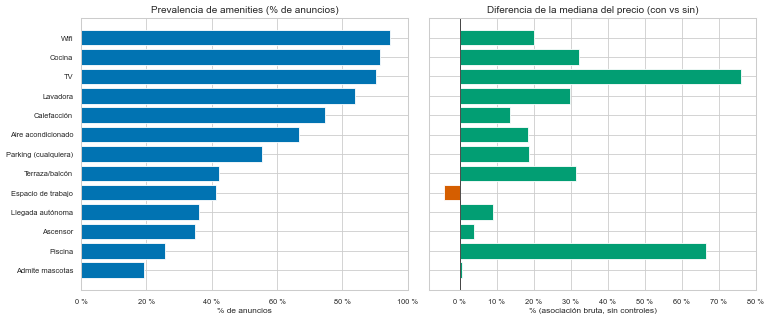

In [37]:
viz.fig_amenities(findings);

In [38]:
am = pd.DataFrame(D["amenities"]).set_index("nombre")
lectura(f"**Lectura.** La amenity más frecuente es {am['prevalencia_pct'].idxmax()} "
        f"({fmt.pct1(am['prevalencia_pct'].max())} de los anuncios). La mayor diferencia bruta de mediana es la de "
        f"{am['prima_pct'].idxmax()} ({fmt.signo_pct(am['prima_pct'].max())}). Es una diferencia sin controles: los "
        "anuncios con o sin una amenity también difieren en tamaño, tipo y zona. La regresión del notebook 02 "
        "estima la asociación de varias amenities manteniendo constantes esos factores.")

**Lectura.** La amenity más frecuente es Wifi (94,7 % de los anuncios). La mayor diferencia bruta de mediana es la de TV (+76,0 %). Es una diferencia sin controles: los anuncios con o sin una amenity también difieren en tamaño, tipo y zona. La regresión del notebook 02 estima la asociación de varias amenities manteniendo constantes esos factores.

## Conclusiones del análisis exploratorio

- Las dos fuentes se unen sin perder anuncios y casi todos reciben datos del INE de su distrito censal.
- El precio es muy asimétrico y depende sobre todo del tipo y el tamaño del alojamiento.
- Las ciudades difieren en precio, pero también en el tipo de oferta, en la concentración de anfitriones y en las
  licencias declaradas: comparar ciudades exige controlar esas diferencias.
- A simple vista la renta de la zona ordena poco los precios entre ciudades. El notebook 02 contrasta formalmente
  la relación renta-precio dentro de cada ciudad y con una regresión que controla el resto de factores.